In [3]:
#hora1

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# 1. Carga de datos multivariados (datos ambientales)
df = pd.read_csv('datos_ambiental_evaluacion_tema9.csv', index_col='estacion')
num_cols = ['pm10_ugm3', 'no2_ppb', 'ruido_db']

# 2. Imputación de valores faltantes con la mediana
df_clean = df[num_cols].fillna(df[num_cols].median())

# 3. Estandarización Z-Score (Media=0, DesvEst=1)
scaler_z = StandardScaler()
df_z = pd.DataFrame(
    scaler_z.fit_transform(df_clean), 
    index=df_clean.index, 
    columns=df_clean.columns
)
# 4. Escalamiento Min-Max (Rango [0, 1])
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(df_clean), 
    index=df_clean.index, 
    columns=df_clean.columns
)
print("--- Matriz Estandarizada Z-Score ---")
print(df_z)

--- Matriz Estandarizada Z-Score ---
               pm10_ugm3   no2_ppb  ruido_db
estacion                                    
Centro          0.261513  0.375457  0.626849
San Jerónimo   -1.220394 -0.684001 -0.744383
Wanchaq         1.743420  1.713719  1.508355
San Sebastián  -0.610197 -0.219326 -0.058767
Poroy          -0.174342 -1.185849 -1.332054


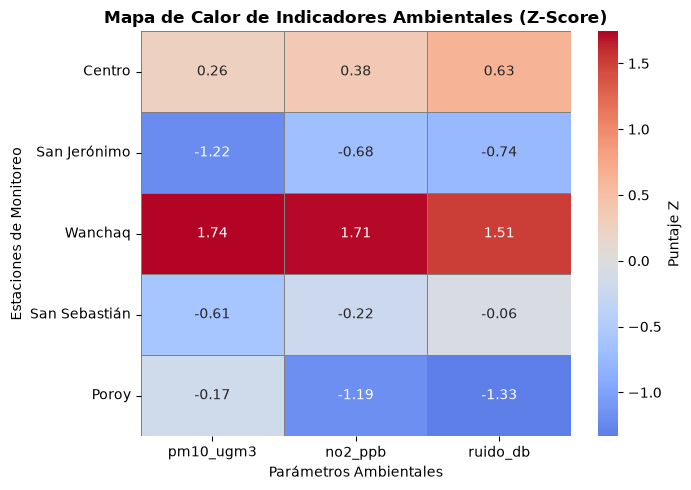

In [4]:
#hora 2

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

# Mapa de Calor con Paleta Divergente 'coolwarm' centrada en 0 (Z-Score)
sns.heatmap(df_z, 
            cmap='coolwarm', 
            center=0, 
            annot=True, 
            fmt='.2f', 
            linewidths=0.5, 
            linecolor='gray',
            cbar_kws={'label': 'Puntaje Z'})

plt.title('Mapa de Calor de Indicadores Ambientales (Z-Score)', fontsize=12, fontweight='bold')
plt.xlabel('Parámetros Ambientales')
plt.ylabel('Estaciones de Monitoreo')
plt.tight_layout()
plt.show()

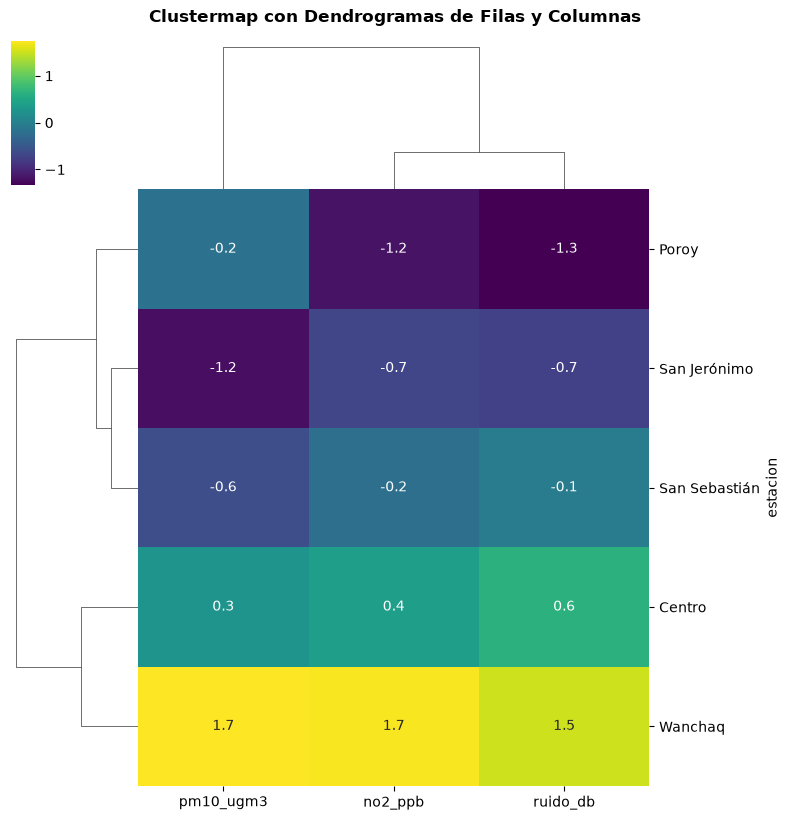

In [5]:
#hora 3

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Clustermap con Clustering Jerárquico (Métrica Euclidiana, Enlace Ward)
g = sns.clustermap(df_z,
                   metric='euclidean',
                   method='ward',
                   cmap='viridis',
                   annot=True,
                   fmt='.1f',
                   figsize=(8, 8),
                   dendrogram_ratio=(0.2, 0.2),
                   cbar_pos=(0.02, 0.8, 0.03, 0.18))

g.figure.suptitle('Clustermap con Dendrogramas de Filas y Columnas', 
                  fontsize=12, fontweight='bold', y=1.02)
plt.show()

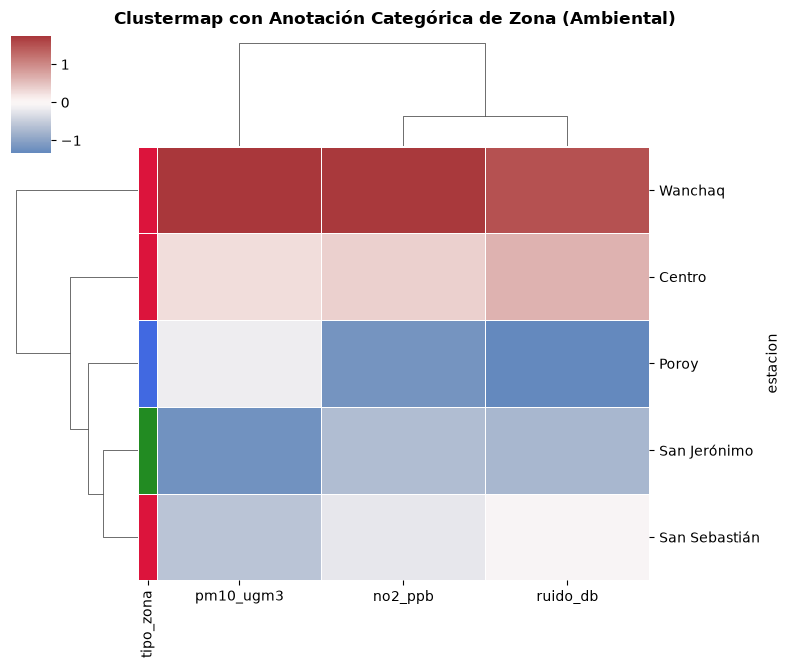

In [8]:
#hora 4

import seaborn as sns
import matplotlib.pyplot as plt

# Definición de barra de colores para anotación categórica
zona_colors = df['tipo_zona'].map({
    'Urbana': 'crimson', 
    'Valle': 'forestgreen', 
    'Altoandina': 'royalblue'
})

g_annot = sns.clustermap(df_z,
                         row_colors=zona_colors,
                         cmap='vlag',
                         center=0,
                         linewidths=0.5,
                         figsize=(8, 6.5))

g_annot.figure.suptitle('Clustermap con Anotación Categórica de Zona (Ambiental)', 
                        fontsize=12, fontweight='bold', y=1.02)
plt.show()

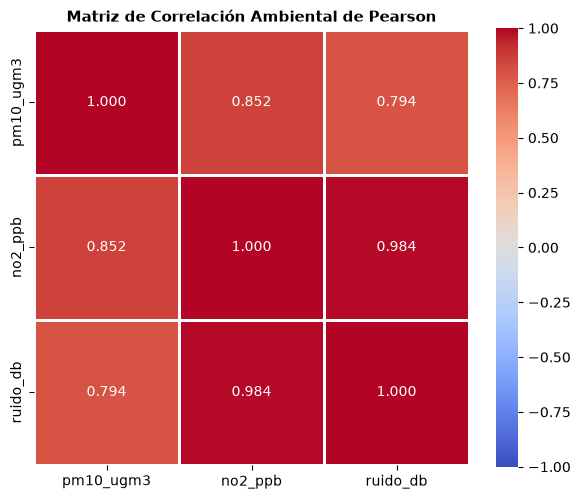

Nasaysayaat a naipablaak ti ladawan kas 'mapa_calor_correlacion_hd.png'.


In [9]:
#hora 5

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Panagkalkulo iti Matriz de Correlación de Pearson
corr_matrix = df_clean.corr()

# 2. Panangisagana iti canvas ti grapiko
plt.figure(figsize=(6, 5))

# 3. Panangpartuat iti Mapa de Calor nga addaan iti paleta a coolwarm
sns.heatmap(corr_matrix, 
            annot=True, 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1, 
            fmt='.3f', 
            square=True, 
            linewidths=1.0)

plt.title('Matriz de Correlación Ambiental de Pearson', fontsize=11, fontweight='bold')
plt.tight_layout()

# 4. Panangeksport iti nangato a resolusion (300 DPI)
plt.savefig('mapa_calor_correlacion_hd.png', dpi=300, bbox_inches='tight')
plt.show()

print("Nasaysayaat a naipablaak ti ladawan kas 'mapa_calor_correlacion_hd.png'.")

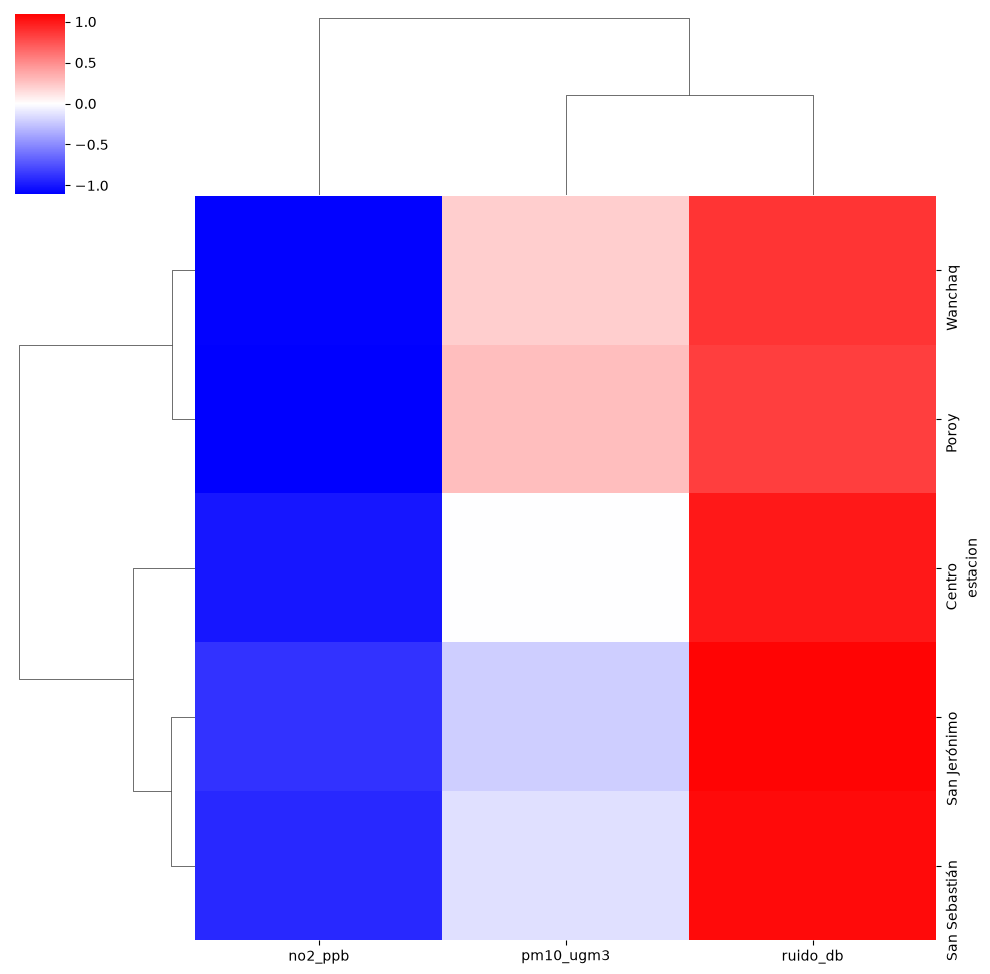

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Asignar los datos limpios de tu entorno a la variable del ejercicio
matriz_data = df_clean

# scale = "row": estandarizar por fila (restar media de la fila y dividir entre su desv. estándar)
matriz_row_z = matriz_data.sub(matriz_data.mean(axis=1), axis=0).div(matriz_data.std(axis=1), axis=0)

g = sns.clustermap(matriz_row_z,
                   method='ward',
                   metric='euclidean',
                   cmap='bwr',       # Paleta equivalente azul-blanco-rojo
                   center=0)
plt.show()


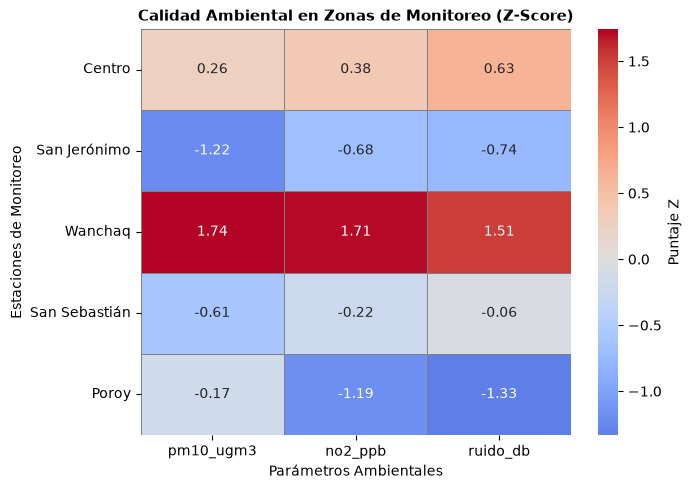

In [13]:
#PARTE C

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Creacion del DataFrame
datos = {
    'estacion': ['Centro', 'San Jerónimo', 'Wanchaq', 'San Sebastián', 'Poroy'],
    'pm10_ugm3': [45.0, 28.0, 62.0, 35.0, np.nan],
    'no2_ppb': [18.2, 12.5, 25.4, 15.0, 9.8],
    'ruido_db': [72, 58, 81, 65, 52]
}
df = pd.DataFrame(datos).set_index('estacion')

# 2. Imputacion del valor faltante con la mediana
num_cols = ['pm10_ugm3', 'no2_ppb', 'ruido_db']
df_clean = df[num_cols].fillna(df[num_cols].median())

# 3. Estandarizacion Z-Score
scaler = StandardScaler()
df_z = pd.DataFrame(scaler.fit_transform(df_clean), 
                    index=df_clean.index, 
                    columns=num_cols)

# 4. Mapa de calor divergente centrado en 0
plt.figure(figsize=(7, 5))
sns.heatmap(df_z, 
            cmap='coolwarm', 
            center=0, 
            annot=True, 
            fmt='.2f', 
            linewidths=0.5,
            linecolor='gray',
            cbar_kws={'label': 'Puntaje Z'})
plt.title('Calidad Ambiental en Zonas de Monitoreo (Z-Score)', fontsize=11, fontweight='bold')
plt.xlabel('Parámetros Ambientales')
plt.ylabel('Estaciones de Monitoreo')
plt.tight_layout()
plt.show()

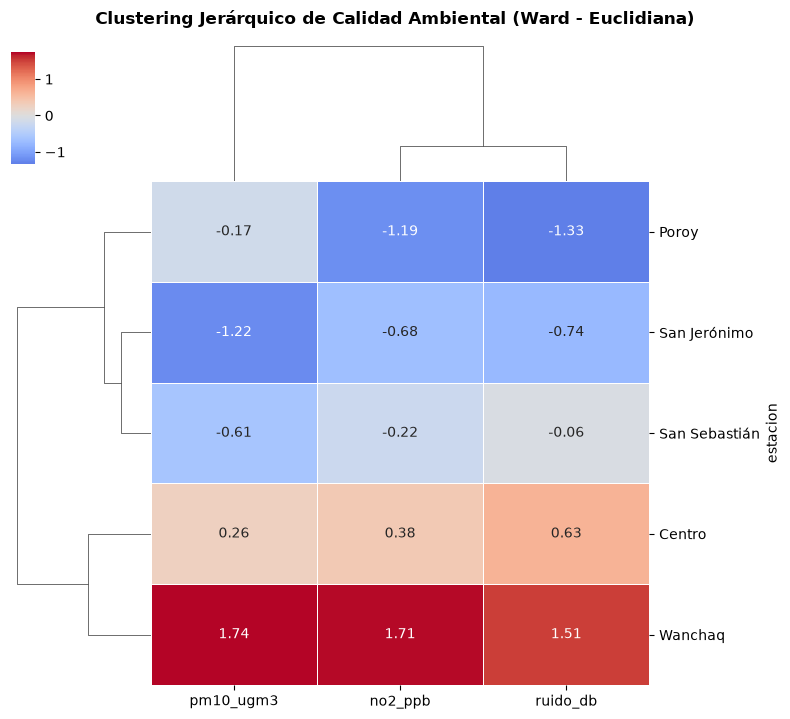

In [14]:
#PARTE D
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Carga e imputacion de datos ambientales
df = pd.read_csv('datos_ambiental_evaluacion_tema9.csv', index_col='estacion')
num_cols = ['pm10_ugm3', 'no2_ppb', 'ruido_db']
df_clean = df[num_cols].fillna(df[num_cols].median())

# Estandarizacion Z-score
scaler = StandardScaler()
df_z = pd.DataFrame(scaler.fit_transform(df_clean), 
                    index=df_clean.index, 
                    columns=num_cols)

# Clustermap jerarquico (Distancia Euclidiana + Metodo Ward)
g = sns.clustermap(df_z,
                   metric='euclidean',
                   method='ward',
                   cmap='coolwarm',
                   center=0,
                   annot=True,
                   fmt='.2f',
                   linewidths=0.5,
                   figsize=(8, 7),
                   dendrogram_ratio=(0.22, 0.22),
                   cbar_pos=(0.02, 0.8, 0.03, 0.16))

g.figure.suptitle('Clustering Jerárquico de Calidad Ambiental (Ward - Euclidiana)', 
                  fontsize=12, fontweight='bold', y=1.02)

# Exportacion en alta resolucion a 300 DPI
plt.savefig('clustermap_ambiental_300dpi.png', dpi=300, bbox_inches='tight')
plt.show()